# Postergación de etiquetado – visualización de la formulación compacta
Modelo MILP estocástico (árbol de 11 nodos) resuelto con **PuLP + HiGHS** (sin Gurobi).

- `datos.py`: **pega aquí el Anexo A** (árbol, probabilidades, demanda). Hoy tiene datos de ejemplo.
- `modelo.py`: formulación (FO, R1–R15), resolución y gráficos.

In [1]:
import importlib, datos, modelo
importlib.reload(datos); importlib.reload(modelo)
%matplotlib inline

## 1. Resolver una política
`PL=0` a stock · `PL=2..5` híbrida · `contra_pedido=True` contra pedido. Cualquier parámetro de la Tabla 2 se puede sobrescribir (ej. `Cb_bl=1000`).

In [2]:
res = modelo.resolver(PL=2)
modelo.resumen(res)
res['nodos']

Politica: hibrida PL=2 | estado: Optimal | costo esperado: $1,071,131
  set-ups $13,100 | inventario $1,058,031 | atrasos $0
  productos postergables elegidos (vino, etiqueta): [(1, 1), (1, 2)]


,padre,prob,horas,estanques
nodo,,,,
1,NaN,1.000000,47.94008,14.0
2,1.0,0.300000,67.17844,16.0
3,1.0,0.400000,54.06884,11.0
4,1.0,0.300000,29.21750,5.0
5,2.0,0.210000,30.79256,0.0
6,2.0,0.090000,22.46844,0.0
7,3.0,0.133333,21.71860,0.0
8,3.0,0.133333,21.22972,0.0
9,3.0,0.133333,20.74084,0.0


## 2. Árbol de escenarios

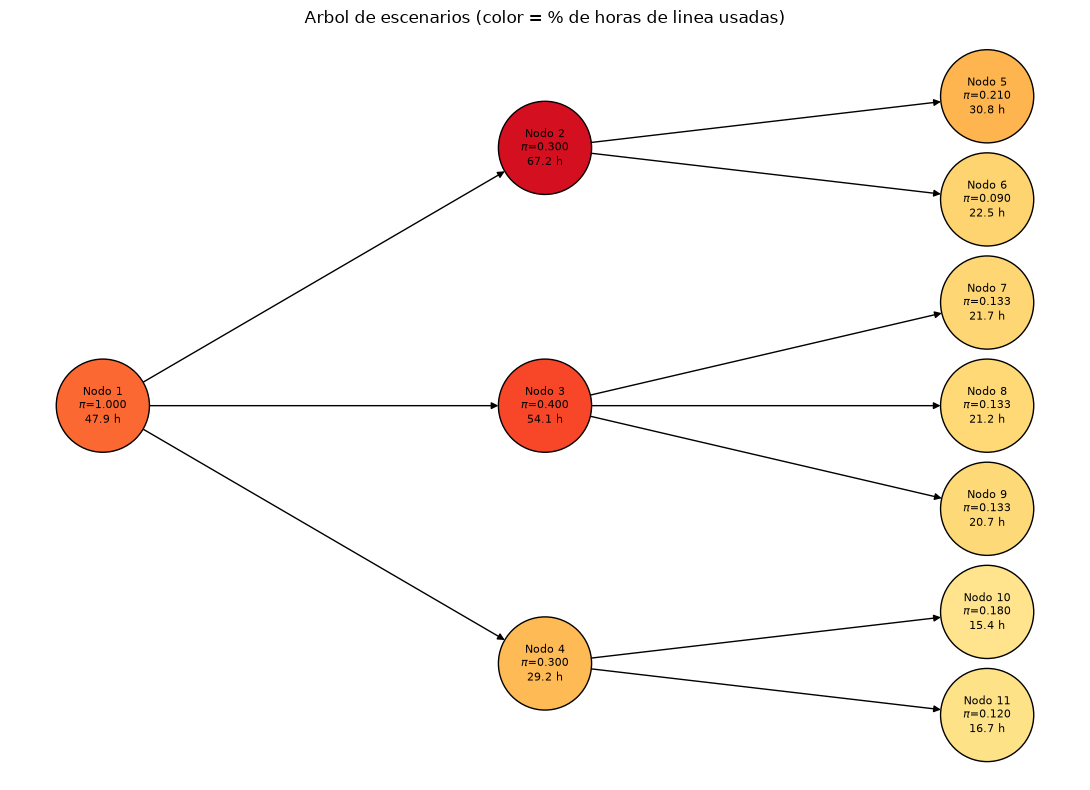

In [3]:
modelo.graficar_arbol(res);

## 3. Decisiones por nodo

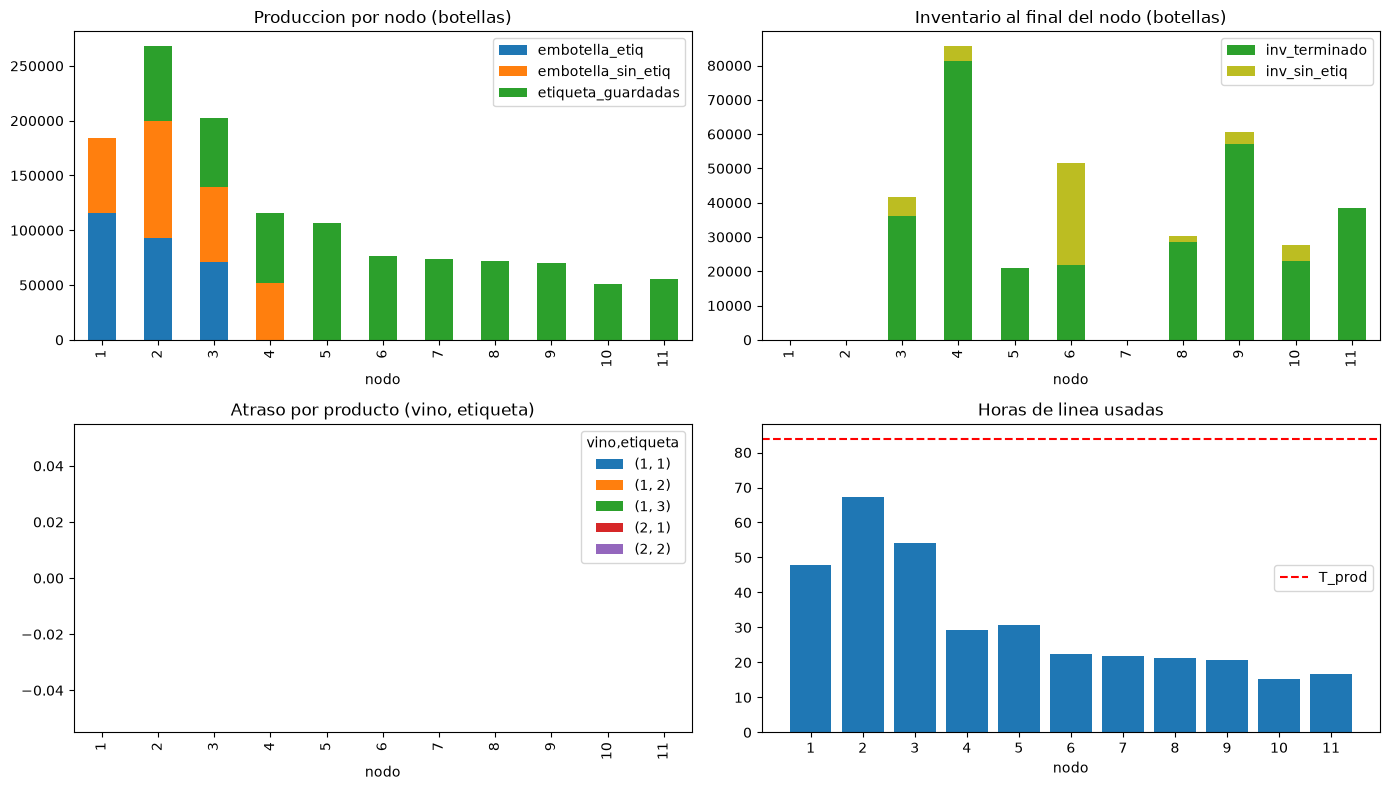

In [4]:
modelo.graficar_decisiones(res);

## 4. Detalle por producto y por vino

In [5]:
res['productos'].round(1)

,nodo,vino,etiqueta,demanda,embotella_etiq,etiqueta_guardadas,inv_terminado,atraso,setup_bl,setup_l
0,1,1,1,23525,0.0,0.0,0.0,0.0,0,0
1,1,1,2,24328,0.0,0.0,0.0,0.0,0,0
2,1,1,3,20368,38150.0,0.0,0.0,0.0,1,0
3,1,2,1,21080,39387.0,0.0,0.0,0.0,1,0
4,1,2,2,22991,38048.0,0.0,0.0,0.0,1,0
5,2,1,1,53218,0.0,53218.0,0.0,0.0,0,1
6,2,1,2,15184,0.0,15184.0,0.0,0.0,0,1
7,2,1,3,38150,25765.0,0.0,0.0,0.0,1,0
8,2,2,1,39387,34115.0,0.0,0.0,0.0,1,0
9,2,2,2,38048,33440.0,0.0,0.0,0.0,1,0


In [6]:
res['vinos'].round(1)

,nodo,vino,embotella_sin_etiq,inv_sin_etiq,setup_b,estanques,vacio_ultimo
0,1,1,68402.0,0.0,1,8.0,0.0
1,1,2,0.0,0.0,0,6.0,0.2
2,2,1,106402.0,0.0,1,10.0,0.1
3,2,2,0.0,0.0,0,6.0,0.9
4,3,1,68446.0,5549.0,1,7.0,0.5
5,3,2,0.0,0.0,0,4.0,0.0
6,4,1,51543.0,4452.0,1,4.0,0.1
7,4,2,0.0,0.0,0,1.0,1.0
8,5,1,0.0,0.0,0,0.0,0.0
9,5,2,0.0,0.0,0,0.0,0.0


## 5. Comparación de políticas

,estado,costo,setups,inventario,atrasos,postergables
politica,,,,,,
a stock,Optimal,1.918302e+06,13650.0,1.904652e+06,0.000000e+00,[]
hibrida PL=2,Optimal,1.071131e+06,13100.0,1.058031e+06,0.000000e+00,"[(1, 1), (1, 2)]"
hibrida PL=3,Optimal,7.934790e+05,11550.0,7.819290e+05,0.000000e+00,"[(1, 1), (1, 2), (1, 3)]"
hibrida PL=4,Optimal,7.046160e+05,12550.0,6.920660e+05,0.000000e+00,"[(1, 1), (1, 2), (1, 3), (2, 1)]"
hibrida PL=5,Optimal,6.171643e+05,10550.0,6.066143e+05,0.000000e+00,"[(1, 1), (1, 2), (1, 3), (2, 1), (2, 2)]"
contra pedido,Optimal,1.861098e+09,15000.0,0.000000e+00,1.861083e+09,[]


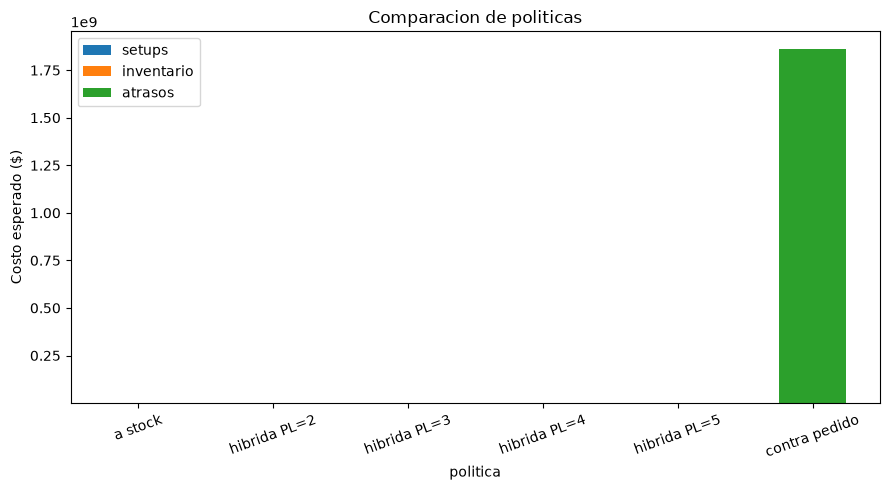

In [7]:
tabla = modelo.comparar_politicas()
display(tabla)
modelo.graficar_comparacion(tabla);

## 6. Sensibilidad (ejemplo): costo de atraso

In [8]:
for cb in [100, 1000, 15000]:
    r = modelo.resolver(PL=2, Cb_bl=cb)
    print(f'Cb_bl={cb}:'); modelo.resumen(r)

Cb_bl=100:
Politica: hibrida PL=2 | estado: Optimal | costo esperado: $1,071,131
  set-ups $13,100 | inventario $1,058,031 | atrasos $0
  productos postergables elegidos (vino, etiqueta): [(1, 1), (1, 2)]


Cb_bl=1000:
Politica: hibrida PL=2 | estado: Optimal | costo esperado: $1,071,131
  set-ups $13,100 | inventario $1,058,031 | atrasos $0
  productos postergables elegidos (vino, etiqueta): [(1, 1), (1, 2)]


Cb_bl=15000:
Politica: hibrida PL=2 | estado: Optimal | costo esperado: $1,071,131
  set-ups $13,100 | inventario $1,058,031 | atrasos $0
  productos postergables elegidos (vino, etiqueta): [(1, 1), (1, 2)]
